# Evaluación de YOLO11s-seg (AutoFish) sobre el dataset Paraná

Carga el modelo entrenado en `yolo11s_seg_autofish_colab.ipynb` (clase única `fish`) y lo prueba **sin reentrenar** sobre el dataset del Paraná (`dataset/`, 6 especies, clase única `pescado`).

1. Métricas globales y **por especie**: IoU de máscara, precisión, recall, F1, mAP50 y mAP50-95 (caja y máscara).
2. Galerías: **20 mejores** (IoU más alto), **20 con menor confianza** y **20 con peor IoU**.
3. Celda final: inferencia sobre una carpeta de ejemplos (`DIR_EX`), con máscara predicha y, si la imagen es del dataset Paraná, también la máscara ground truth.

## 1 · Configuración

In [12]:
from pathlib import Path

# ── Rutas ────────────────────────────────────────────────────────────────────
WEIGHTS   = r"C:\Users\juanm\Documents\GitHub\fish_cv_pfc\runs\yolo11s_seg_fish_autofish-20261112T135539Z-1-001\yolo11s_seg_fish_autofish\weights\best.pt"   # <- pesos entrenados en Colab (subir al repo)
DATA_DIR  = "dataset"                   # dataset Paraná (images/<split>, labels/<split>)
SPLIT     = "test"                      # "test", "val", "train" o "all"
IMGSZ     = 1024                        # el mismo que en el entrenamiento
OUT_DIR   = "outputs/eval_parana"

# ── Inferencia ───────────────────────────────────────────────────────────────
PRED_CONF = 0.6    # umbral para el análisis por imagen / galerías (model.val usa conf=0.001 para mAP)
NMS_IOU   = 0.6
IOU_TP    = 0.5     # IoU de máscara para contar un TP en precisión/recall
DEVICE    = None    # None = auto (GPU si hay), o "cpu" / 0

# ── Colores (RGB) ────────────────────────────────────────────────────────────
COLOR_PRED_RGB = (0, 220, 0)      # máscara predicha
COLOR_GT_RGB   = (255, 60, 60)    # máscara ground truth
ALPHA = 0.40

N_GALLERY = 20

## 2 · Entorno y carga del modelo

In [13]:
# !pip -q install -U ultralytics
import json, cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from ultralytics import YOLO

ROOT = Path(DATA_DIR).resolve()
OUT  = Path(OUT_DIR); OUT.mkdir(parents=True, exist_ok=True)
assert Path(WEIGHTS).exists(), f"No encuentro {WEIGHTS}: subí los pesos al repo o ajustá WEIGHTS"
model = YOLO(WEIGHTS)
print("Modelo:", WEIGHTS, "| tarea:", model.task, "| clases:", model.names)

# imágenes del split elegido; la especie es el prefijo del nombre ("boga__123.jpg")
splits = ["train", "val", "test"] if SPLIT == "all" else [SPLIT]
IMGS = sorted(p for s in splits for p in (ROOT/"images"/s).iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"})
species_of = lambda p: p.stem.split("__")[0]
SPECIES = sorted({species_of(p) for p in IMGS})
print(len(IMGS), "imágenes |", {s: sum(species_of(p) == s for p in IMGS) for s in SPECIES})

Modelo: C:\Users\juanm\Documents\GitHub\fish_cv_pfc\runs\yolo11s_seg_fish_autofish-20261112T135539Z-1-001\yolo11s_seg_fish_autofish\weights\best.pt | tarea: segment | clases: {0: 'fish'}
209 imágenes | {'boga': 32, 'dorado': 28, 'palometa': 53, 'sabalo': 40, 'surubi_pintado': 15, 'tararira': 41}


## 3 · mAP / precisión / recall con Ultralytics (global y por especie)
Se valida el mismo modelo sobre cada especie por separado (lista de imágenes en un `.txt` + `data.yaml` temporal con una sola clase). Las métricas P/R/mAP son las de Ultralytics (conf=0.001, IoU NMS 0.6; P y R en el punto de máximo F1).

In [14]:
import yaml
tmp = (OUT/"_val").resolve(); tmp.mkdir(exist_ok=True)

def val_subset(name, files):
    txt = tmp/f"{name}.txt"; txt.write_text("\n".join(p.as_posix() for p in files))
    yml = tmp/f"{name}.yaml"
    yml.write_text(yaml.safe_dump({"path": ROOT.as_posix(), "train": txt.as_posix(), "val": txt.as_posix(),
                                   "test": txt.as_posix(), "names": {0: "fish"}}))
    m = model.val(data=str(yml), split="val", imgsz=IMGSZ, conf=0.001, iou=NMS_IOU, batch=8, workers=0,
                  device=DEVICE, plots=False, verbose=False, project=str(OUT), name="_valrun", exist_ok=True)
    return {"imgs": len(files),
            "P(B)": m.box.mp, "R(B)": m.box.mr, "mAP50(B)": m.box.map50, "mAP50-95(B)": m.box.map,
            "P(M)": m.seg.mp, "R(M)": m.seg.mr, "mAP50(M)": m.seg.map50, "mAP50-95(M)": m.seg.map}

rows = {"GLOBAL": val_subset("global", IMGS)}
for s in SPECIES:
    rows[s] = val_subset(s, [p for p in IMGS if species_of(p) == s])
df_map = pd.DataFrame(rows).T
df_map["imgs"] = df_map["imgs"].astype(int)
df_map.iloc[:, 1:] = df_map.iloc[:, 1:].astype(float).round(4)
display(df_map)

Ultralytics 8.4.174  Python-3.11.9 torch-2.14.0+cu130 CUDA:0 (NVIDIA GeForce GTX 1650, 4096MiB)
YOLO11s-seg summary (fused): 113 layers, 10,067,203 parameters, 0 gradients, 32.9 GFLOPs
val: Fast image access  (ping: 0.10.0 ms, read: 2099.6426.0 MB/s, size: 949.8 KB)
val: Scanning C:\Users\juanm\Documents\GitHub\fish_cv_pfc\dataset\labels\test... 209 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 209/209 1.8Kit/s 0.1s<0.1s
val: New cache created: C:\Users\juanm\Documents\GitHub\fish_cv_pfc\dataset\labels\test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 27/27 1.8it/s 15.3s0.5s
                   all        209        209     0.0428      0.234     0.0213    0.00721     0.0398      0.187     0.0145    0.00495
Speed: 0.7ms preprocess, 40.5ms inference, 0.0ms loss, 5.4ms postprocess per image
Ultralytics 8.4.174  Python-3.11.9 torch-2.14.0+cu130 CUDA:0 (NVIDIA GeForce GTX 16

,imgs,P(B),R(B),mAP50(B),mAP50-95(B),P(M),R(M),mAP50(M),mAP50-95(M)
GLOBAL,209,0.0428,0.2344,0.0213,0.0072,0.0398,0.1866,0.0145,0.0050
boga,32,0.0330,0.2500,0.0158,0.0049,0.0330,0.2500,0.0130,0.0041
dorado,28,0.0473,0.3929,0.0396,0.0234,0.0726,0.1071,0.0266,0.0189
palometa,53,0.0516,0.1887,0.0261,0.0094,0.0496,0.1698,0.0158,0.0057
sabalo,40,0.0710,0.2500,0.0433,0.0171,0.0568,0.2000,0.0303,0.0106
surubi_pintado,15,0.0079,0.1333,0.0020,0.0004,0.0199,0.0667,0.0052,0.0007
tararira,41,0.0440,0.2927,0.0309,0.0096,0.0486,0.2439,0.0265,0.0088


## 4 · Análisis por imagen (IoU de máscara, confianza, TP/FP/FN)
Se rasterizan las máscaras GT (polígonos YOLO-seg) y las predichas a baja resolución (lado mayor 512 px) y se calcula el IoU de máscara.
- **IoU por imagen** = media, sobre los peces GT, del mejor IoU con alguna predicción (0 si no hay predicciones).
- **Confianza por imagen** = confianza máxima entre las predicciones (0 si no detecta nada).
- **TP/FP/FN**: emparejamiento greedy por confianza con IoU de máscara ≥ `IOU_TP`.

In [15]:
RES = 512

def read_gt(img_path):
    """polígonos GT normalizados [(N,2), ...] desde labels/<split>/<stem>.txt"""
    lp = ROOT/"labels"/Path(img_path).parent.name/f"{Path(img_path).stem}.txt"
    polys = []
    if lp.exists():
        for ln in lp.read_text().splitlines():
            v = np.array(ln.split()[1:], dtype=float)
            if len(v) >= 6: polys.append(v.reshape(-1, 2))
    return polys

def raster(polys_px, shape):
    out = []
    for p in polys_px:
        m = np.zeros(shape, np.uint8); cv2.fillPoly(m, [np.round(p).astype(np.int32)], 1); out.append(m.astype(bool))
    return np.array(out).reshape(len(out), *shape)

def iou_mat(a, b):
    if len(a) == 0 or len(b) == 0: return np.zeros((len(a), len(b)))
    a = a.reshape(len(a), -1).astype(np.float32); b = b.reshape(len(b), -1).astype(np.float32)
    inter = a @ b.T; return inter / (a.sum(1)[:, None] + b.sum(1)[None] - inter + 1e-9)

def predict(path, conf=PRED_CONF):
    r = model.predict(str(path), imgsz=IMGSZ, conf=conf, iou=NMS_IOU, device=DEVICE, verbose=False)[0]
    polys = [p.copy() for p in r.masks.xy] if r.masks is not None else []
    return polys, r.boxes.conf.cpu().numpy(), r.orig_shape      # polígonos en px de la imagen original

def iou_image(gt_norm, polys, h, w):
    """(M[n_gt, n_pred], shape) con IoU de máscara a resolución reducida"""
    k = RES / max(h, w); shp = (int(round(h*k)), int(round(w*k)))
    return iou_mat(raster([g * [w, h] * k for g in gt_norm], shp), raster([q * k for q in polys], shp))

PRED, rows = {}, []
for p in IMGS:
    polys, conf, (h, w) = predict(p)
    PRED[p] = (polys, conf)
    gt = read_gt(p)
    M = iou_image(gt, polys, h, w)                            # (n_gt, n_pred)
    best = M.max(1) if M.shape[1] else np.zeros(len(gt))
    tp = 0; used = np.zeros(len(gt), bool)                    # emparejamiento greedy por confianza
    for i in np.argsort(-conf):
        if M.shape[0] == 0: break
        j = np.where(~used, M[:, i], -1).argmax()
        if M[j, i] >= IOU_TP and not used[j]: used[j] = True; tp += 1
    rows.append(dict(img=p.name, path=str(p), species=species_of(p), n_gt=len(gt), n_pred=len(polys),
                     iou=float(best.mean()) if len(best) else np.nan, conf=float(conf.max()) if len(conf) else 0.0,
                     tp=tp, fp=len(polys) - tp, fn=len(gt) - tp))
df = pd.DataFrame(rows)
df.to_csv(OUT/"por_imagen.csv", index=False)
print(len(df), "imágenes analizadas | sin detección:", int((df.n_pred == 0).sum()))
df.head()

209 imágenes analizadas | sin detección: 13


,img,path,species,n_gt,n_pred,iou,conf,tp,fp,fn
0,boga__183244729_319660969.jpeg,C:\Users\juanm\Documents\GitHub\fish_cv_pfc\da...,boga,1,3,0.001056,0.863751,0,3,1
1,boga__193489307_339903766.jpeg,C:\Users\juanm\Documents\GitHub\fish_cv_pfc\da...,boga,1,2,0.038294,0.756409,0,2,1
2,boga__248526686_444084808.jpeg,C:\Users\juanm\Documents\GitHub\fish_cv_pfc\da...,boga,1,0,0.000000,0.000000,0,0,1
3,boga__257136308_461207294.jpeg,C:\Users\juanm\Documents\GitHub\fish_cv_pfc\da...,boga,1,4,0.044656,0.762872,0,4,1
4,boga__328373279_595015312.jpg,C:\Users\juanm\Documents\GitHub\fish_cv_pfc\da...,boga,1,0,0.000000,0.000000,0,0,1


### 4.1 · Tabla por especie (IoU, precisión, recall, F1 + mAP)

In [16]:
def agg(g):
    tp, fp, fn = g.tp.sum(), g.fp.sum(), g.fn.sum()
    return pd.Series(dict(imgs=len(g), peces_gt=g.n_gt.sum(), IoU_medio=g.iou.mean(), IoU_mediana=g.iou.median(),
                          conf_media=g.conf.mean(), precision=tp/(tp+fp+1e-9), recall=tp/(tp+fn+1e-9),
                          F1=2*tp/(2*tp+fp+fn+1e-9), sin_deteccion=(g.n_pred == 0).sum()))
by_sp = df.groupby("species")[list(df.columns)].apply(agg)
by_sp.loc["GLOBAL"] = agg(df)
final = by_sp.join(df_map[["mAP50(B)", "mAP50-95(B)", "mAP50(M)", "mAP50-95(M)"]])
final = final.astype({"imgs": int, "peces_gt": int, "sin_deteccion": int}).round(4)
final.to_csv(OUT/"metricas_por_especie.csv")
display(final)

,imgs,peces_gt,IoU_medio,IoU_mediana,conf_media,precision,recall,F1,sin_deteccion,mAP50(B),mAP50-95(B),mAP50(M),mAP50-95(M)
species,,,,,,,,,,,,,
boga,32,32,0.1638,0.0145,0.7928,0.0273,0.1875,0.0476,2,0.0158,0.0049,0.0130,0.0041
dorado,28,28,0.2552,0.1102,0.7731,0.0413,0.1786,0.0671,2,0.0396,0.0234,0.0266,0.0189
palometa,53,53,0.1758,0.0595,0.8271,0.0297,0.1509,0.0497,1,0.0261,0.0094,0.0158,0.0057
sabalo,40,40,0.1871,0.0265,0.6906,0.0510,0.2000,0.0812,5,0.0433,0.0171,0.0303,0.0106
surubi_pintado,15,15,0.1056,0.0439,0.8081,0.0096,0.0667,0.0168,0,0.0020,0.0004,0.0052,0.0007
tararira,41,41,0.2151,0.0372,0.7475,0.0419,0.1951,0.0690,3,0.0309,0.0096,0.0265,0.0088
GLOBAL,209,209,0.1894,0.0439,0.7715,0.0339,0.1722,0.0566,13,0.0213,0.0072,0.0145,0.0050


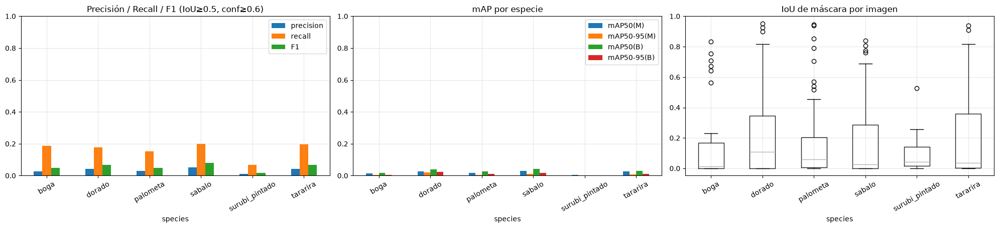

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(20, 4.8))
sp_only = final.drop(index="GLOBAL")
sp_only[["precision", "recall", "F1"]].plot.bar(ax=ax[0], ylim=(0, 1), title=f"Precisión / Recall / F1 (IoU≥{IOU_TP}, conf≥{PRED_CONF})")
sp_only[["mAP50(M)", "mAP50-95(M)", "mAP50(B)", "mAP50-95(B)"]].plot.bar(ax=ax[1], ylim=(0, 1), title="mAP por especie")
df.boxplot(column="iou", by="species", ax=ax[2]); ax[2].set_title("IoU de máscara por imagen"); plt.suptitle("")
for a in ax: a.grid(alpha=.3); a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(OUT/"metricas_por_especie.png", dpi=120); plt.show()

## 5 · Galerías: 20 mejores · 20 de menor confianza · 20 de peor IoU
Se dibuja la máscara **GT** (`COLOR_GT_RGB`) y la **predicha** (`COLOR_PRED_RGB`) con su contorno; donde se superponen se mezclan los colores.

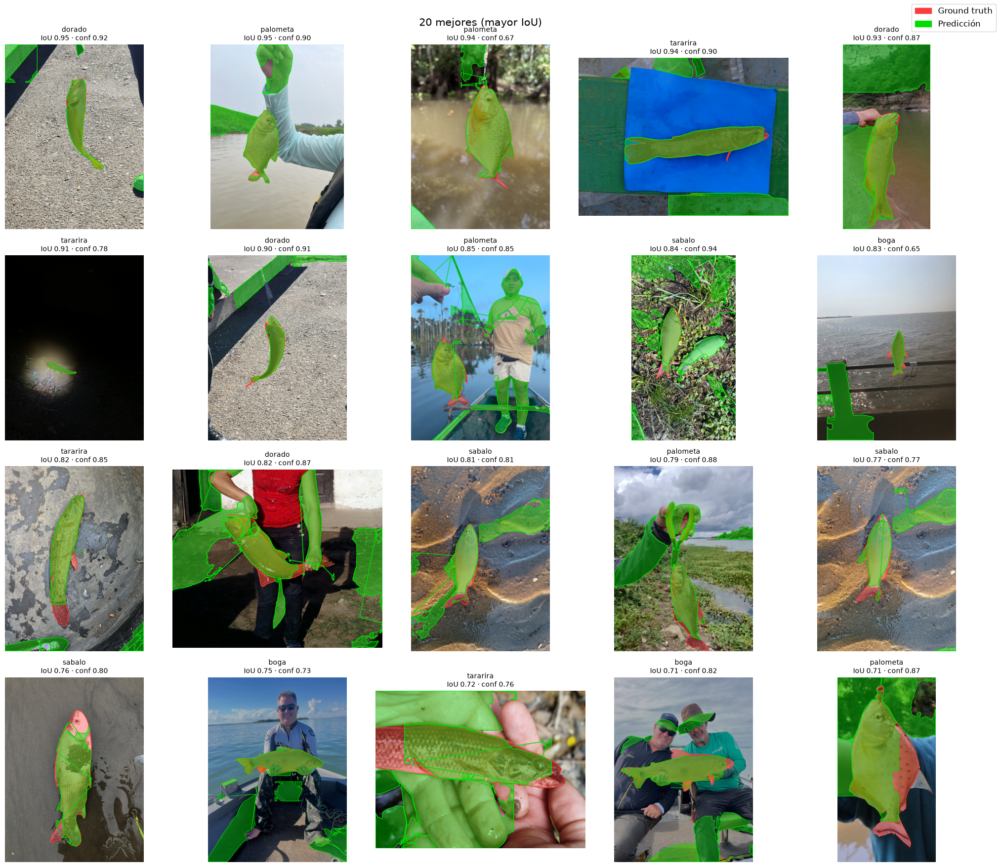

In [18]:
from matplotlib.patches import Patch

def overlay(img_rgb, polys, color, alpha=ALPHA, thick=3):
    ov = img_rgb.copy()
    for p in polys: cv2.fillPoly(ov, [np.round(p).astype(np.int32)], color)
    out = cv2.addWeighted(ov, alpha, img_rgb, 1 - alpha, 0)
    for p in polys: cv2.polylines(out, [np.round(p).astype(np.int32)], True, color, thick)
    return out

def render(path, pred_polys, with_gt=True):
    im = cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB); h, w = im.shape[:2]
    t = max(2, int(max(h, w) / 400))
    if with_gt: im = overlay(im, [g * [w, h] for g in read_gt(path)], COLOR_GT_RGB, thick=t)
    return overlay(im, pred_polys, COLOR_PRED_RGB, thick=t)

def legend(fig, with_gt=True):
    hs = ([Patch(color=np.array(COLOR_GT_RGB)/255, label="Ground truth")] if with_gt else []) + \
         [Patch(color=np.array(COLOR_PRED_RGB)/255, label="Predicción")]
    fig.legend(handles=hs, loc="upper right", fontsize=12)

def gallery(sub, title, fname, cols=5):
    rows_ = int(np.ceil(len(sub) / cols))
    fig, ax = plt.subplots(rows_, cols, figsize=(4.2*cols, 4.4*rows_)); ax = np.atleast_1d(ax).ravel()
    for a, (_, r) in zip(ax, sub.iterrows()):
        a.imshow(render(r.path, PRED[Path(r.path)][0])); a.axis("off")
        a.set_title(f"{r.species}\nIoU {r.iou:.2f} · conf {r.conf:.2f}", fontsize=10)
    for a in ax[len(sub):]: a.axis("off")
    legend(fig); plt.suptitle(title, fontsize=15); plt.tight_layout(); plt.savefig(OUT/fname, dpi=110); plt.show()

gallery(df.sort_values(["iou", "conf"], ascending=False).head(N_GALLERY), f"{N_GALLERY} mejores (mayor IoU)", "galeria_mejores.png")

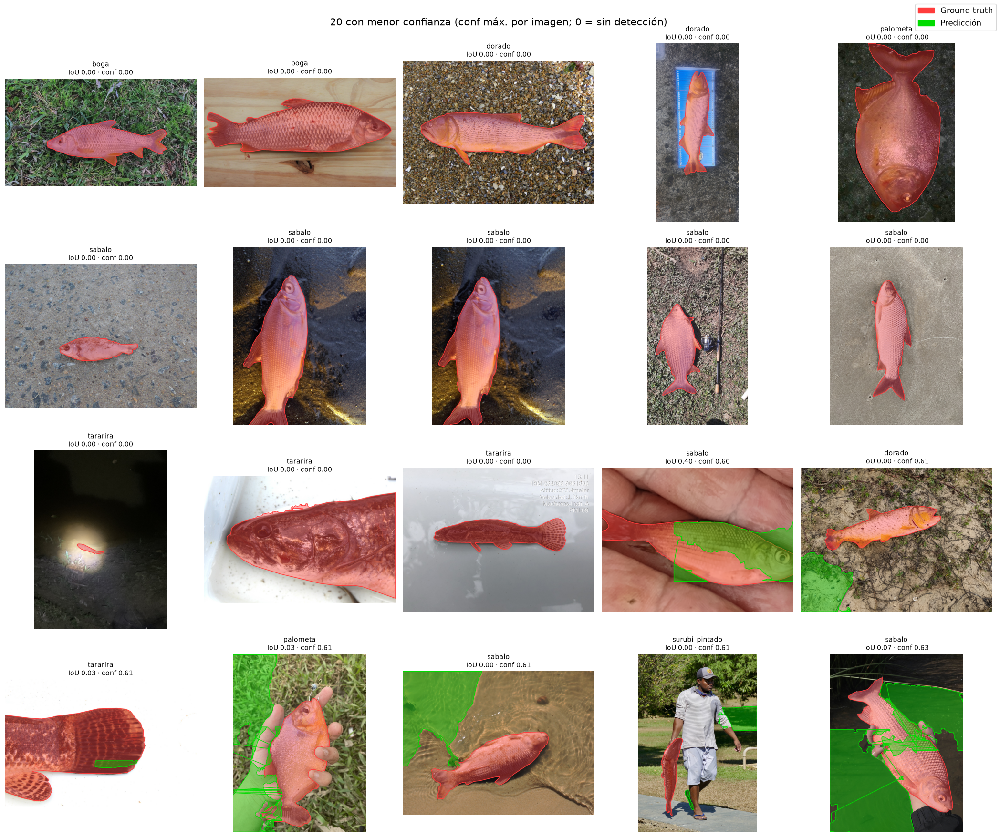

In [19]:
gallery(df.sort_values(["conf", "iou"]).head(N_GALLERY), f"{N_GALLERY} con menor confianza (conf máx. por imagen; 0 = sin detección)", "galeria_menor_conf.png")

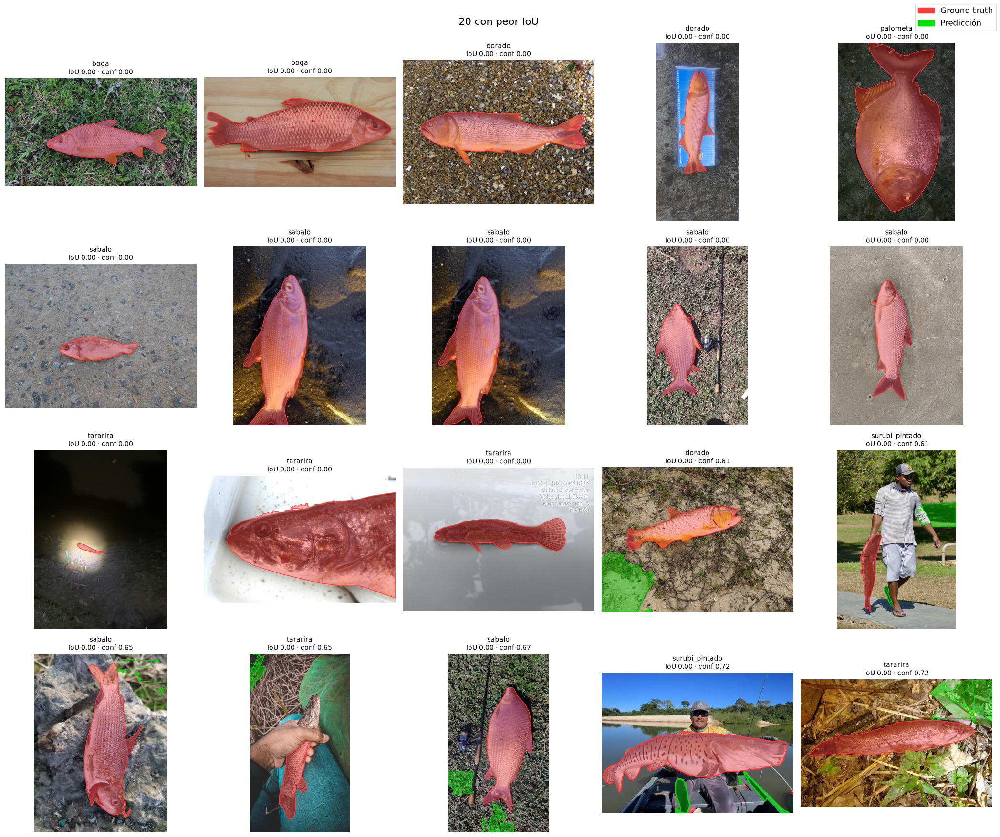

In [20]:
gallery(df.sort_values(["iou", "conf"]).head(N_GALLERY), f"{N_GALLERY} con peor IoU", "galeria_peor_iou.png")

## 6 · Ejemplos propios (`DIR_EX`)
Define `DIR_EX` con una carpeta de imágenes. Para cada una se dibuja la **máscara predicha** (`COLOR_PRED_RGB`). Si el nombre de la imagen corresponde a una del dataset Paraná (se busca en `labels/*/<nombre>.txt`), se dibuja también el **ground truth** (`COLOR_GT_RGB`) y se informa el IoU.

13 imágenes en examples


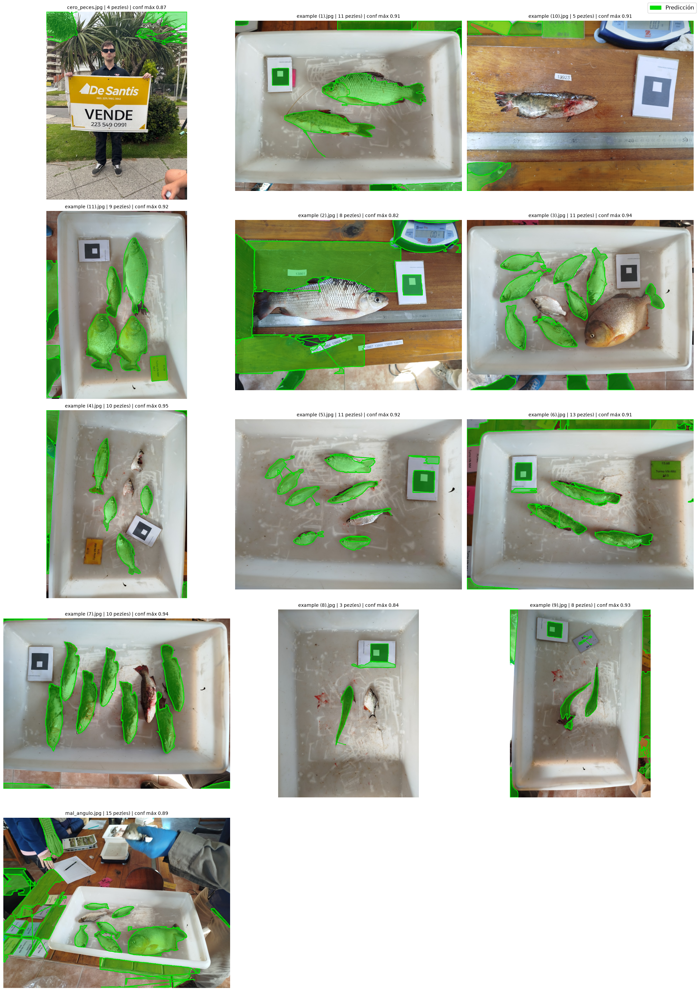

In [21]:
DIR_EX = "examples"      # <- carpeta con las imágenes a analizar
EX_CONF = PRED_CONF      # umbral de confianza para estos ejemplos
EX_COLS = 3

exs = sorted(p for p in Path(DIR_EX).iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"})
print(len(exs), "imágenes en", DIR_EX)

def find_gt(p):
    """imagen del dataset Paraná con el mismo nombre (si existe etiqueta GT)"""
    for s in ("test", "val", "train"):
        if (ROOT/"labels"/s/f"{p.stem}.txt").exists(): return ROOT/"images"/s/p.name
    return None

cols = max(1, min(EX_COLS, len(exs))); rows_ = int(np.ceil(len(exs) / cols))
fig, ax = plt.subplots(rows_, cols, figsize=(7*cols, 6*rows_)); ax = np.atleast_1d(ax).ravel()
any_gt = False
for a, p in zip(ax, exs):
    polys, conf, (h, w) = predict(p, EX_CONF)
    gt_ref = find_gt(p)
    title = f"{p.name} | {len(polys)} pez(es)" + (f" | conf máx {conf.max():.2f}" if len(conf) else "")
    if gt_ref:
        any_gt = True
        M = iou_image(read_gt(gt_ref), polys, h, w)
        title += f" | IoU {M.max(1).mean() if M.shape[1] else 0:.2f}"
    a.imshow(render(gt_ref or p, polys, with_gt=gt_ref is not None)); a.axis("off"); a.set_title(title, fontsize=10)
for a in ax[len(exs):]: a.axis("off")
legend(fig, with_gt=any_gt); plt.tight_layout(); plt.savefig(OUT/"ejemplos.png", dpi=110); plt.show()